# KIT end-date prediction

The aim of this project is to estimate when kitting will finish for each sales order. A simple one-day baseline is analyzed, then tested whether order details could improve the prediction. The main measure is whether the predicted date is within one day of the actual date.

## 1. Load and inspect the historical data

In [1]:
import pandas as pd

#%pip install pyarrow
#%pip install fastparquet

In [2]:
pd.set_option('display.max_columns',None)

In [3]:
import warnings
warnings.filterwarnings('ignore')

In [4]:
df = pd.read_parquet(r"C:\Users\admin\Downloads\Dell Data\train.parquet")

# View first five records
df.head()

,sales_order_id,buid,site,orig_wo_id,tie_num,mcid,order_amt,quantity_produced,line_qty,cfs_flag,is_cfi,alt_type_desc,lob_desc,family_parent_desc,family_desc,download_date,kit_start,kit_end,est_ship_date
0,1025548771,11.0,KHO,22067915245,1.0,3JU,42935.31840,8.0,8.0,0,1,NSYJLWFYJI XTQZYNTSX LWTZU UGZ,UTBJWJILJ,LJSYWD,LJSYWD HXU,2025-10-15,2025-10-16,2025-10-17,2025-10-31
1,1027927868,11.0,KHO,22095717945,1.0,KHO,33128.74827,2.0,2.0,0,1,NSYJLWFYJI XTQZYNTSX LWTZU UGZ,UTBJWJILJ,HMFRUNTS,HMFRUNTS AXFSWS,2025-12-11,2025-12-12,2025-12-14,2026-03-16
2,1029939204,11.0,KHO,22112237255,1.0,KHO,17238.22614,1.0,1.0,0,1,NSYJLWFYJI XTQZYNTSX LWTZU UGZ,UTBJWJILJ,HMFRUNTS,HMFRUNTS UJ,2026-01-29,2026-01-30,2026-02-03,2026-06-17
3,1023379512,11.0,KHO,22082951775,1.0,3JU,34306.97076,6.0,6.0,0,1,NSYJLWFYJI XTQZYNTSX LWTZU UGZ,UTBJWJILJ,RNZWF,RNZWF UJ,2025-11-19,2025-11-29,2025-11-30,2025-11-12
4,1017735495,707.0,KHO,21983065475,1.0,KHO,6261.03846,1.0,1.0,0,0,NSYJLWFYJI XTQZYNTSX LWTZU UGZ,UTBJWJILJ,MZWFHFS,MZWFHFS UJ,2025-04-01,2025-04-03,2025-04-04,2025-04-16


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 179853 entries, 0 to 179852
Data columns (total 19 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   sales_order_id      179853 non-null  int64         
 1   buid                179853 non-null  float64       
 2   site                179853 non-null  object        
 3   orig_wo_id          179853 non-null  int64         
 4   tie_num             179853 non-null  float64       
 5   mcid                179853 non-null  object        
 6   order_amt           179853 non-null  float64       
 7   quantity_produced   179853 non-null  float64       
 8   line_qty            179853 non-null  float64       
 9   cfs_flag            179853 non-null  int64         
 10  is_cfi              179853 non-null  int64         
 11  alt_type_desc       179853 non-null  object        
 12  lob_desc            179853 non-null  object        
 13  family_parent_desc  179853 no

In [6]:
df.shape

(179853, 19)

In [7]:
df.describe()

,sales_order_id,buid,orig_wo_id,tie_num,order_amt,quantity_produced,line_qty,cfs_flag,is_cfi,download_date,kit_start,kit_end,est_ship_date
count,1.798530e+05,179853.000000,1.798530e+05,179853.000000,1.798530e+05,179853.000000,179853.000000,179853.000000,179853.000000,179848,179853,179853,179853
mean,1.000724e+09,111.339866,2.204052e+10,1.053888,4.028525e+04,3.331048,3.106965,0.046616,0.508298,2025-08-13 01:27:39.000933888,2025-08-16 10:47:57.670097408,2025-08-17 18:55:27.797701632,2025-09-05 21:15:36.584877568
min,3.874252e+08,11.000000,2.195945e+10,1.000000,0.000000e+00,0.000000,1.000000,0.000000,0.000000,2025-02-05 00:00:00,2025-03-04 00:00:00,2025-03-10 00:00:00,1900-01-01 00:00:00
25%,1.018994e+09,11.000000,2.200181e+10,1.000000,5.102372e+03,1.000000,1.000000,0.000000,0.000000,2025-05-16 00:00:00,2025-05-21 00:00:00,2025-05-22 00:00:00,2025-06-13 00:00:00
50%,1.022566e+09,11.000000,2.204060e+10,1.000000,1.562000e+04,2.000000,2.000000,0.000000,1.000000,2025-08-14 00:00:00,2025-08-15 00:00:00,2025-08-17 00:00:00,2025-09-10 00:00:00
75%,1.026069e+09,11.000000,2.207591e+10,1.000000,4.197329e+04,6.000000,6.000000,0.000000,1.000000,2025-11-04 00:00:00,2025-11-07 00:00:00,2025-11-07 00:00:00,2025-12-04 00:00:00
max,1.030020e+09,3232.000000,2.211296e+10,9.000000,8.079212e+06,40.000000,16.000000,1.000000,1.000000,2026-01-31 00:00:00,2026-01-31 00:00:00,2026-03-08 00:00:00,2026-12-16 00:00:00
std,1.156756e+08,457.853729,4.191114e+07,0.286859,9.632891e+04,2.845440,2.739585,0.210815,0.499933,NaN,NaN,NaN,NaN


In [8]:
df.isnull().sum()

sales_order_id        0
buid                  0
site                  0
orig_wo_id            0
tie_num               0
mcid                  0
order_amt             0
quantity_produced     0
line_qty              0
cfs_flag              0
is_cfi                0
alt_type_desc         0
lob_desc              0
family_parent_desc    0
family_desc           0
download_date         5
kit_start             0
kit_end               0
est_ship_date         0
dtype: int64

In [9]:
# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


## 2. Order records

An order can appear on several rows when it contains different product families. Repeated records check before building an order-level target.

In [10]:
print("Rows:", len(df))

print("Unique sales orders:",
      df["sales_order_id"].nunique())

print("Unique order-family combinations:",
      df[["sales_order_id", "family_desc"]]
      .drop_duplicates().shape[0])

print("Duplicate order-family combinations:",
      df.duplicated(
          subset=["sales_order_id", "family_desc"]
      ).sum())

Rows: 179853
Unique sales orders: 172234
Unique order-family combinations: 179843
Duplicate order-family combinations: 10


In [11]:
# Find sales orders appearing more than once
order_counts = df["sales_order_id"].value_counts()

multiple_orders = order_counts[order_counts > 1]

print("Orders with multiple records:", len(multiple_orders))

# Inspect one example
example_id = multiple_orders.index[0]

df.loc[
    df["sales_order_id"] == example_id,
    ["sales_order_id", "family_desc", "kit_start", "kit_end"]
]

Orders with multiple records: 6397


,sales_order_id,family_desc,kit_start,kit_end
23505,1018101021,RNSJWFQBJQQX UJ,2025-04-19,2025-04-22
23514,1018101021,XPDQDSCUJ,2025-04-19,2025-04-22
46851,1018101021,RCL610X 8XKU JSY KN,2025-04-19,2025-04-22
110878,1018101021,RC9116S KN,2025-04-19,2025-04-22
148480,1018101021,RC7116S KN,2025-04-19,2025-04-22


In [12]:
# Count distinct kit_end dates within each sales order
end_dates = df.groupby("sales_order_id")["kit_end"].nunique()

print("Orders with one kit_end date:",
      (end_dates == 1).sum())

print("Orders with multiple kit_end dates:",
      (end_dates > 1).sum())

Orders with one kit_end date: 172234
Orders with multiple kit_end dates: 0


In [13]:
start_dates = df.groupby("sales_order_id")["kit_start"].nunique()

In [14]:
print("Orders with one kit_start date:",
      (start_dates == 1).sum())

print("Orders with multiple kit_start dates:",
      (start_dates > 1).sum())

Orders with one kit_start date: 172234
Orders with multiple kit_start dates: 0


## 3. KIT duration and data quality

In [15]:
df["kit_cycle_hours"] = (
    df["kit_end"] - df["kit_start"]
).dt.total_seconds() / 3600

print(df["kit_cycle_hours"].describe())

print("Negative durations:",
      (df["kit_cycle_hours"] < 0).sum())

print("Zero durations:",
      (df["kit_cycle_hours"] == 0).sum())

print("Missing values:")
print(df.isna().sum())

count    179853.000000
mean         32.125035
std          39.105917
min        -600.000000
25%          24.000000
50%          24.000000
75%          48.000000
max        1824.000000
Name: kit_cycle_hours, dtype: float64
Negative durations: 734
Zero durations: 35082
Missing values:
sales_order_id        0
buid                  0
site                  0
orig_wo_id            0
tie_num               0
mcid                  0
order_amt             0
quantity_produced     0
line_qty              0
cfs_flag              0
is_cfi                0
alt_type_desc         0
lob_desc              0
family_parent_desc    0
family_desc           0
download_date         5
kit_start             0
kit_end               0
est_ship_date         0
kit_cycle_hours       0
dtype: int64


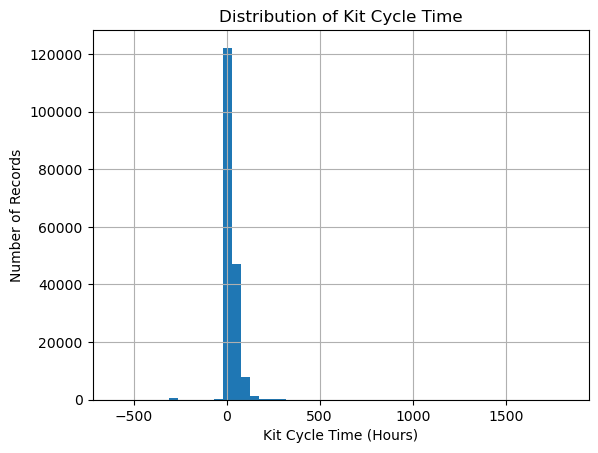

In [16]:
import matplotlib.pyplot as plt

df["kit_cycle_hours"].hist(bins=50)

plt.xlabel("Kit Cycle Time (Hours)")
plt.ylabel("Number of Records")
plt.title("Distribution of Kit Cycle Time")
plt.show()

In [17]:
df[["kit_start", "kit_end", "kit_cycle_hours"]].head(10)

,kit_start,kit_end,kit_cycle_hours
0,2025-10-16,2025-10-17,24.0
1,2025-12-12,2025-12-14,48.0
2,2026-01-30,2026-02-03,96.0
3,2025-11-29,2025-11-30,24.0
4,2025-04-03,2025-04-04,24.0
5,2025-05-28,2025-05-29,24.0
6,2025-07-01,2025-07-02,24.0
7,2025-09-10,2025-09-10,0.0
8,2025-08-16,2025-08-19,72.0
9,2025-11-13,2025-11-15,48.0


In [18]:
print("Kit start times:")
print(df["kit_start"].dt.time.value_counts().head(10))

print("\nKit end times:")
print(df["kit_end"].dt.time.value_counts().head(10))

Kit start times:
kit_start
00:00:00    179853
Name: count, dtype: int64

Kit end times:
kit_end
00:00:00    179853
Name: count, dtype: int64


In [19]:
print(df["kit_cycle_hours"].value_counts().head(15))

kit_cycle_hours
 24.0     87105
 0.0      35082
 48.0     30639
 72.0     16407
 96.0      6268
 120.0     1567
 144.0      872
 168.0      515
-264.0      278
-288.0      209
-48.0       120
 192.0      116
 312.0       95
 264.0       86
 216.0       73
Name: count, dtype: int64


In [20]:
df["kit_cycle_days"] = (
    df["kit_end"] - df["kit_start"]
).dt.days

In [21]:
negative_orders = df[df["kit_cycle_days"] < 0]

negative_orders[
    ["sales_order_id", "site", "family_desc",
     "kit_start", "kit_end", "kit_cycle_days"]
].head(15)

,sales_order_id,site,family_desc,kit_start,kit_end,kit_cycle_days
465,1020850367,KHO,JQJRJSYT UJ,2025-07-08,2025-06-27,-11
873,1020912983,KHO,HMFRUNTS UJ,2025-06-27,2025-06-26,-1
953,1026592472,KHO,IJSYTS UJ,2025-11-14,2025-11-12,-2
1244,1020961824,KHO,LQFIJBFYJW UJ,2025-07-08,2025-06-27,-11
1493,1020963295,KHO,YJCTRF UJ,2025-07-08,2025-06-27,-11
1663,1020933864,KHO,XMJQITS UJ,2025-07-08,2025-06-26,-12
2056,1020301692,KHO,XUNYEJW JC500W,2025-07-08,2025-06-27,-11
2245,1020950271,KHO,CH760-HMFRUNTS,2025-07-08,2025-06-26,-12
2280,1020950529,KHO,NXQJWT 1Z UJ,2025-07-08,2025-06-27,-11
2496,1020946449,KHO,RC7116S KN,2025-07-08,2025-06-26,-12


In [22]:
negative_orders["site"].value_counts()

site
KHO    734
Name: count, dtype: int64

In [23]:
# Count all records from KHO
kho_total = (df["site"] == "KHO").sum()

# Count negative records from KHO
kho_negative = (
    (df["site"] == "KHO") &
    (df["kit_cycle_days"] < 0)
).sum()

# Calculate percentage
kho_percentage = (kho_negative / kho_total) * 100

print("Total KHO records:", kho_total)
print("Negative KHO records:", kho_negative)
print("Percentage:", round(kho_percentage, 2), "%")

Total KHO records: 179853
Negative KHO records: 734
Percentage: 0.41 %


### Negative durations

These rows have a KIT end date earlier than the start date. I kept them for the data-quality review but excluded them from the modeling dataset. The original dates are not corrected because there is no way to know which timestamp is wrong.

In [24]:
print("Negative KIT records:", len(negative_orders))

print("\nNegative duration statistics:")
print(negative_orders["kit_cycle_days"].describe())

print("\nMost common negative durations:")
print(negative_orders["kit_cycle_days"].value_counts().head(10))

print("\nNegative records by start month:")
print(
    negative_orders["kit_start"]
    .dt.to_period("M")
    .value_counts()
    .sort_index()
)

print("\nColumns available:")
print(negative_orders.columns.tolist())

Negative KIT records: 734

Negative duration statistics:
count    734.000000
mean     -10.151226
std        5.681906
min      -25.000000
25%      -12.000000
50%      -11.000000
75%      -10.000000
max       -1.000000
Name: kit_cycle_days, dtype: float64

Most common negative durations:
kit_cycle_days
-11    278
-12    209
-2     120
-25     51
-1      37
-10     19
-7       6
-3       5
-8       3
-13      3
Name: count, dtype: int64

Negative records by start month:
kit_start
2025-06     22
2025-07    562
2025-11    118
2026-01     32
Freq: M, Name: count, dtype: int64

Columns available:
['sales_order_id', 'buid', 'site', 'orig_wo_id', 'tie_num', 'mcid', 'order_amt', 'quantity_produced', 'line_qty', 'cfs_flag', 'is_cfi', 'alt_type_desc', 'lob_desc', 'family_parent_desc', 'family_desc', 'download_date', 'kit_start', 'kit_end', 'est_ship_date', 'kit_cycle_hours', 'kit_cycle_days']


In [25]:
print("Most common KIT start dates:")
print(
    negative_orders["kit_start"]
    .value_counts()
    .head(10)
)

print("\nMost common KIT end dates:")
print(
    negative_orders["kit_end"]
    .value_counts()
    .head(10)
)

print("\nNegative records by line of business:")
print(
    negative_orders["lob_desc"]
    .value_counts()
    .head(10)
)

print("\nUnique affected sales orders:")
print(
    negative_orders["sales_order_id"].nunique()
)

Most common KIT start dates:
kit_start
2025-07-08    562
2025-11-14    118
2026-01-30     32
2025-06-27     17
2025-06-26      5
Name: count, dtype: int64

Most common KIT end dates:
kit_end
2025-06-27    278
2025-06-26    226
2025-11-12    100
2025-06-13     54
2026-01-28     20
2025-06-28     19
2025-11-13     17
2026-01-27      5
2026-01-23      3
2026-01-22      3
Name: count, dtype: int64

Negative records by line of business:
lob_desc
UTBJWJILJ                      666
MDUJWHTSAJWLJI NSKWFX YWFSX     26
IJQQ XYTWFLJ TJR                24
IFYF UWTYJHYNTS FUU YWFSX       17
IJQQ SJYBTWPNSL                  1
Name: count, dtype: int64

Unique affected sales orders:
721


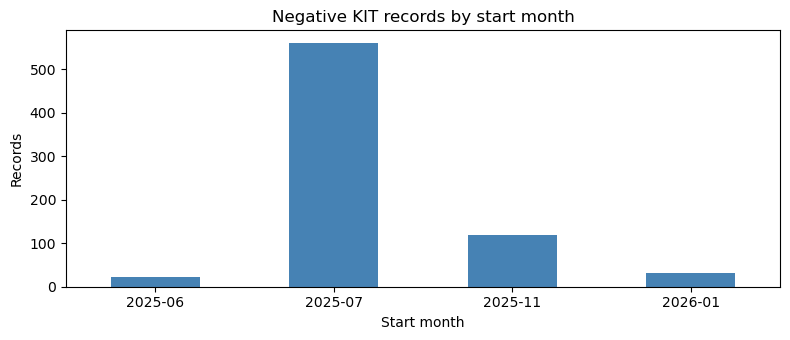

In [26]:
# Plot where the negative-duration records are concentrated
negative_by_month = (negative_orders["kit_start"].dt.to_period("M")
                     .value_counts().sort_index())
ax = negative_by_month.plot(kind="bar", figsize=(8, 3.5), color="steelblue")
ax.set(title="Negative KIT records by start month", xlabel="Start month", ylabel="Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Same-day completion and product-family differences

In [27]:
zero_orders = df[df["kit_cycle_days"] == 0]

print("Zero-duration records:", len(zero_orders))

print("Unique sales orders:",
      zero_orders["sales_order_id"].nunique())

print("Top 10 product families:")
print(zero_orders["family_desc"].value_counts().head(10))

Zero-duration records: 35082
Unique sales orders: 33550
Top 10 product families:
family_desc
XMJQITS UJ           2976
HTQJYT UJ            2969
YJCTRF UJ            2277
HMFRUNTS UJ          2131
LQFIJBFYJW UJ        1377
FWQNSLYTS UJ         1311
JFLQJ RTZSYFNS UJ     941
NXQJWT 1Z UJ          932
YWFINSLMTZXJ UJ       801
XTRJWANQQJ UJ         749
Name: count, dtype: int64


In [28]:
# Compare same-day completion rates across product families
total_by_family = df.groupby("family_desc")["sales_order_id"].size()
zero_by_family = (
    df.loc[df["kit_cycle_days"] == 0]
    .groupby("family_desc")["sales_order_id"]
    .size()
)

family_summary = pd.DataFrame({
    "Total_Records": total_by_family,
    "Zero_Records": zero_by_family
}).fillna({"Zero_Records": 0})

family_summary["Zero_Percentage"] = (
    family_summary["Zero_Records"] / family_summary["Total_Records"] * 100
)

family_summary.sort_values(
    "Zero_Percentage", ascending=False
).head(10)

,Total_Records,Zero_Records,Zero_Percentage
family_desc,,,
LNGGTSXHWJJP IXX,1,1.0,100.000000
YMZSIJW AFQQJD-RJ5024 TJR IXX,2,2.0,100.000000
BNHMNYF HXU,1,1.0,100.000000
WJI GQZKK TJRWIXX,1,1.0,100.000000
ACAI-4510H-MFSLJW,4,3.0,75.000000
HFXF GQFSHF IXX,168,123.0,73.214286
XMTWNCI JCK900,71,50.0,70.422535
RFWX CW8620Y HHX UJ,3,2.0,66.666667
RFWX CW8620Y IZC UJ,3,2.0,66.666667


In [29]:
family_summary[
    family_summary["Total_Records"] >= 100
].sort_values(
    by="Zero_Percentage",
    ascending=False
).head(10)

,Total_Records,Zero_Records,Zero_Percentage
family_desc,,,
HFXF GQFSHF IXX,168,123.0,73.214286
GWFETX AXFSWS,130,70.0,53.846154
XMJQITS TJRCJIXX,164,77.0,46.951220
QJTSF IXX,127,55.0,43.307087
DJYN XRFQQKTTY TJRW,687,281.0,40.902475
WJI GQZKK AXFSWS,106,39.0,36.792453
KZLZNONFT UJ,518,183.0,35.328185
WJAJSYTS IXX,539,183.0,33.951763
GZKKFQT HWJJPHMIXX,1084,343.0,31.642066


In [30]:
df["line_qty"].describe()

count    179853.000000
mean          3.106965
std           2.739585
min           1.000000
25%           1.000000
50%           2.000000
75%           6.000000
max          16.000000
Name: line_qty, dtype: float64

In [31]:
df[["line_qty", "kit_cycle_days"]].corr()

,line_qty,kit_cycle_days
line_qty,1.000000,-0.035121
kit_cycle_days,-0.035121,1.000000


In [32]:
valid_df = df[df["kit_cycle_days"] >= 0]

valid_df[["line_qty", "kit_cycle_days"]].corr()

,line_qty,kit_cycle_days
line_qty,1.000000,-0.047007
kit_cycle_days,-0.047007,1.000000


In [33]:
family_duration = valid_df.groupby("family_desc")["kit_cycle_days"].agg(
    ["count", "mean", "median", "std"]
)

family_duration.head(10)

,count,mean,median,std
family_desc,,,,
ACA670K-MZWFHFS,18,1.888889,2.0,1.231398
ACAI-4000B-AFQJ,4,1.500000,1.0,1.000000
ACAI-4000W-GJHPJYYX,7,0.857143,1.0,1.069045
ACAI-4510H-MFSLJW,4,0.500000,0.0,1.000000
ACAI-4520H-XYTBJ,4,1.500000,1.0,1.000000
ACAJ-660-LFQBFD,549,1.613843,1.0,1.151114
ACAJ-6615-GJQKFXY,17,1.470588,1.0,1.545867
ACAU-760-QFSHFXYJW,273,1.820513,1.0,1.662967
ACAU-7625-DTWP,16,1.250000,1.0,0.774597


In [34]:
family_duration[
    family_duration["count"] >= 100
].sort_values(
    "median",
    ascending=False
).head(10)

,count,mean,median,std
family_desc,,,,
RTXX IXX,358,4.435754,4.0,4.717220
RTXX UJ,109,3.000000,3.0,2.755466
XYJJIF IXX,279,2.519713,3.0,1.431457
LRFXYJWKZQQ JC5000,135,2.525926,2.0,1.544512
PJJHMN UJ,778,3.043702,2.0,3.336263
UFQT UNSYT UJ,1331,3.075131,2.0,2.277132
UFQT AJWIJ UJ,1392,2.103448,2.0,1.478118
HTZUJ UJ,151,2.099338,2.0,1.147490
LRFXYJWHMFX JC5000,408,2.245098,2.0,1.700910


In [35]:
# Count product families per sales order

order_complexity = valid_df.groupby(
    "sales_order_id"
)["family_desc"].nunique()

In [36]:
# one duration per sales order

order_duration = valid_df.groupby(
    "sales_order_id"
)["kit_cycle_days"].first()

In [37]:
# Order analysis

order_analysis = pd.DataFrame({
    "num_families": order_complexity,
    "kit_cycle_days": order_duration
})

order_analysis.head()

,num_families,kit_cycle_days
sales_order_id,,
387425162,1,1
390092683,1,1
390133700,1,1
390172930,1,1
390172938,1,1


In [38]:
order_analysis.groupby("num_families")[
    "kit_cycle_days"
].agg(["count", "mean", "median"])

,count,mean,median
num_families,,,
1,165136,1.379941,1.0
2,5478,1.495801,1.0
3,586,1.366894,1.0
4,306,1.199346,1.0
5,7,1.285714,2.0


## 4. Prepare the order-level dataset and time split

Each sales order gets one target duration. The split is chronological so the validation and test sets represent later orders.

In [39]:
# Keep nonnegative durations
valid_df = df[df["kit_cycle_days"] >= 0].copy()

# Create one record per sales order
orders = valid_df.groupby("sales_order_id").agg(
    kit_start=("kit_start", "first"),
    kit_end=("kit_end", "first"),
    kit_cycle_days=("kit_cycle_days", "first"),
    num_families=("family_desc", "nunique")
).reset_index()

print("Order-level dataset shape:", orders.shape)

orders.head()

Order-level dataset shape: (171513, 5)


,sales_order_id,kit_start,kit_end,kit_cycle_days,num_families
0,387425162,2025-04-14,2025-04-15,1,1
1,390092683,2025-04-05,2025-04-06,1,1
2,390133700,2025-05-30,2025-05-31,1,1
3,390172930,2025-04-14,2025-04-15,1,1
4,390172938,2025-04-14,2025-04-15,1,1


In [40]:
# Sort orders by their start date
orders = orders.sort_values("kit_start").reset_index(drop=True)

In [41]:
# Use date boundaries so the same start date cannot fall in two sets
# Training: before October 24
train_orders = orders[
    orders["kit_start"] < "2025-10-24"
].copy()

# Validation: October 24 to December 10
val_orders = orders[
    (orders["kit_start"] >= "2025-10-24") &
    (orders["kit_start"] < "2025-12-11")
].copy()

# Testing: December 11 onward
test_orders = orders[
    orders["kit_start"] >= "2025-12-11"
].copy()

In [42]:
for name, data in [
    ("Train", train_orders),
    ("Validation", val_orders),
    ("Test", test_orders)
]:
    print(
        name,
        "Orders:", len(data),
        "Start:", data["kit_start"].min(),
        "End:", data["kit_start"].max()
    )

print("\nTotal orders:",
      len(train_orders) + len(val_orders) + len(test_orders))

Train Orders: 119335 Start: 2025-03-04 00:00:00 End: 2025-10-23 00:00:00
Validation Orders: 25367 Start: 2025-10-24 00:00:00 End: 2025-12-10 00:00:00
Test Orders: 26811 Start: 2025-12-11 00:00:00 End: 2026-01-31 00:00:00

Total orders: 171513


## 5. One-day baseline

Median of orders completed before the validation cutoff. This gives a simple reference point for the models.

In [43]:
# Only orders completed before validation begins
baseline_history = train_orders[
    train_orders["kit_end"] < "2025-10-24"
]

# Find the typical duration
baseline_days = baseline_history["kit_cycle_days"].median()

print("Baseline prediction:", baseline_days, "days")

Baseline prediction: 1.0 days


In [44]:
val_orders = val_orders.copy()

val_orders["predicted_days"] = baseline_days

val_orders[
    ["kit_cycle_days", "predicted_days"]
].head(10)

,kit_cycle_days,predicted_days
119335,2,1.0
119336,1,1.0
119337,3,1.0
119338,2,1.0
119339,1,1.0
119340,0,1.0
119341,1,1.0
119342,1,1.0
119343,3,1.0
119344,3,1.0


In [45]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(
    val_orders["kit_cycle_days"],
    val_orders["predicted_days"]
)

print("Baseline MAE:", round(mae, 3), "days")

Baseline MAE: 0.831 days


In [46]:
actual = val_orders["kit_cycle_days"]
predicted = val_orders["predicted_days"]

# Exact prediction accuracy
exact_accuracy = (actual == predicted).mean() * 100

# Percentage within one day
within_one_day = (
    (actual - predicted).abs() <= 1
).mean() * 100

# Percentage within two days
within_two_days = (
    (actual - predicted).abs() <= 2
).mean() * 100

print("Exact accuracy:", round(exact_accuracy, 2), "%")
print("Within 1 day:", round(within_one_day, 2), "%")
print("Within 2 days:", round(within_two_days, 2), "%")

Exact accuracy: 45.59 %
Within 1 day: 81.76 %
Within 2 days: 93.93 %


In [47]:
# Prediction error
val_orders["error"] = (
    val_orders["predicted_days"]
    - val_orders["kit_cycle_days"]
)

print("Predicted too early:",
      (val_orders["error"] < 0).mean() * 100)

print("Predicted too late:",
      (val_orders["error"] > 0).mean() * 100)

print("Predicted exactly:",
      (val_orders["error"] == 0).mean() * 100)

Predicted too early: 39.16111483423345
Predicted too late: 15.248157054440808
Predicted exactly: 45.59072811132574


## 6. Check features before modeling

I checked quantity fields and possible leakage before choosing the inputs. In particular, `quantity_produced` may not be known when the prediction is made.

In [48]:
df[
    [
        "order_amt",
        "quantity_produced",
        "line_qty",
        "cfs_flag",
        "is_cfi",
        "alt_type_desc",
        "lob_desc",
        "family_parent_desc"
    ]
].head(10)

,order_amt,quantity_produced,line_qty,cfs_flag,is_cfi,alt_type_desc,lob_desc,family_parent_desc
0,42935.31840,8.0,8.0,0,1,NSYJLWFYJI XTQZYNTSX LWTZU UGZ,UTBJWJILJ,LJSYWD
1,33128.74827,2.0,2.0,0,1,NSYJLWFYJI XTQZYNTSX LWTZU UGZ,UTBJWJILJ,HMFRUNTS
2,17238.22614,1.0,1.0,0,1,NSYJLWFYJI XTQZYNTSX LWTZU UGZ,UTBJWJILJ,HMFRUNTS
3,34306.97076,6.0,6.0,0,1,NSYJLWFYJI XTQZYNTSX LWTZU UGZ,UTBJWJILJ,RNZWF
4,6261.03846,1.0,1.0,0,0,NSYJLWFYJI XTQZYNTSX LWTZU UGZ,UTBJWJILJ,MZWFHFS
5,8384.44635,1.0,1.0,0,0,NSYJLWFYJI XTQZYNTSX LWTZU UGZ,UTBJWJILJ,HTQJYT
6,1529.13615,1.0,1.0,0,0,NSYJLWFYJI XTQZYNTSX LWTZU UGZ,UTBJWJILJ,YJCTRF
7,22694.77059,3.0,3.0,0,0,NSYJLWFYJI XTQZYNTSX LWTZU UGZ,UTBJWJILJ,HMFRUNTS
8,173689.76787,2.0,2.0,0,0,NSYJLWFYJI XTQZYNTSX LWTZU UGZ,IJQQ XYTWFLJ TJR,YMZSIJW AFQQJD RJ5084
9,186866.95605,1.0,1.0,0,1,NSYJLWFYJI XTQZYNTSX LWTZU UGZ,UTBJWJILJ,UFQT AJWIJ


In [49]:
# is quantity same as line quantity?

same_qty = (
    df["quantity_produced"] == df["line_qty"]
)

print("Matching records:", same_qty.sum())

print("Different records:", (~same_qty).sum())

print("Matching percentage:",
      round(same_qty.mean() * 100, 2), "%")

Matching records: 165150
Different records: 14703
Matching percentage: 91.82 %


In [50]:
# Data leakage check
# Calculate the difference
df["qty_difference"] = (
    df["quantity_produced"] - df["line_qty"]
)

# Count each situation
print("Produced more than line quantity:",
      (df["qty_difference"] > 0).sum())

print("Produced less than line quantity:",
      (df["qty_difference"] < 0).sum())

print("Quantities equal:",
      (df["qty_difference"] == 0).sum())

Produced more than line quantity: 14699
Produced less than line quantity: 4
Quantities equal: 165150


In [51]:
#line quantity check
multi_orders = df[
    df["sales_order_id"].duplicated(keep=False)
]

multi_orders[
    ["sales_order_id", "family_desc",
     "line_qty", "quantity_produced", "order_amt"]
].sort_values("sales_order_id").head(20)

,sales_order_id,family_desc,line_qty,quantity_produced,order_amt
144778,390397965,XTUTY TJRW,1.0,4.0,33876.74844
69321,390397965,SJJIQJX TJRW,1.0,4.0,33876.74844
53915,390397965,JQZFSGN TJRW,2.0,4.0,33876.74844
131832,390397983,SJJIQJX TJRW,1.0,4.0,33876.74844
29071,390397983,XTUTY TJRW,1.0,4.0,33876.74844
65151,390397983,JQZFSGN TJRW,2.0,4.0,33876.74844
92137,390438521,UJRGWTPJ IXX,1.0,2.0,6942.22380
148657,390438521,BJCKTWI UJ,1.0,2.0,6942.22380
63703,390438529,UJRGWTPJ IXX,1.0,2.0,6942.22380
44782,390438529,BJCKTWI UJ,1.0,2.0,6942.22380


In [52]:
# Quantity check
qty_check = multi_orders.groupby("sales_order_id").agg(
    total_line_qty=("line_qty", "sum"),
    produced_min=("quantity_produced", "min"),
    produced_max=("quantity_produced", "max"),
    num_records=("line_qty", "size")
)

qty_check.head(10)

,total_line_qty,produced_min,produced_max,num_records
sales_order_id,,,,
390397965,4.0,4.0,4.0,3
390397983,4.0,4.0,4.0,3
390438521,2.0,2.0,2.0,2
390438529,2.0,2.0,2.0,2
390438537,2.0,2.0,2.0,2
390438545,2.0,2.0,2.0,2
390438571,2.0,2.0,2.0,2
390438579,2.0,2.0,2.0,2
390438587,2.0,2.0,2.0,2


In [53]:
# Check if quantity_produced is constant within each order
same_produced = (
    qty_check["produced_min"] == qty_check["produced_max"]
)

# Check if total line quantity matches produced quantity
matches_total = (
    qty_check["total_line_qty"] == qty_check["produced_max"]
)

print("Multi-record orders:", len(qty_check))

print("Orders with constant quantity_produced:",
      same_produced.sum())

print("Orders where total line_qty equals quantity_produced:",
      matches_total.sum())

print("Percentage matching:",
      round(matches_total.mean() * 100, 2), "%")

Multi-record orders: 6397
Orders with constant quantity_produced: 6397
Orders where total line_qty equals quantity_produced: 5725
Percentage matching: 89.5 %


In [54]:
order_qty = df.groupby("sales_order_id")["line_qty"].sum()

orders["total_line_qty"] = (
    orders["sales_order_id"].map(order_qty)
)

print("Dataset shape:", orders.shape)

print("Missing quantities:",
      orders["total_line_qty"].isna().sum())

orders.head()

Dataset shape: (171513, 6)
Missing quantities: 0


,sales_order_id,kit_start,kit_end,kit_cycle_days,num_families,total_line_qty
0,1016524375,2025-03-04,2025-03-14,10,1,1.0
1,1016019103,2025-03-04,2025-03-14,10,1,8.0
2,1016474537,2025-03-04,2025-03-14,10,1,1.0
3,1016483537,2025-03-04,2025-03-14,10,1,1.0
4,1016470895,2025-03-04,2025-03-12,8,1,1.0


In [55]:
train_orders = orders[
    orders["kit_start"] < "2025-10-24"
].copy()

val_orders = orders[
    (orders["kit_start"] >= "2025-10-24") &
    (orders["kit_start"] < "2025-12-11")
].copy()

test_orders = orders[
    orders["kit_start"] >= "2025-12-11"
].copy()

In [56]:
#Target
features = ["total_line_qty", "num_families"]

X_train = train_orders[features]
y_train = train_orders["kit_cycle_days"]

X_val = val_orders[features]
y_val = val_orders["kit_cycle_days"]

## 7. Decision Tree models

With order quantity and number of families.

In [57]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error

model = DecisionTreeRegressor(
    max_depth=3,
    random_state=42
)

model.fit(X_train, y_train)

predictions = model.predict(X_val)

mae = mean_absolute_error(y_val, predictions)

print("Decision Tree MAE:", round(mae, 3), "days")
print("Baseline MAE: 0.831 days")

Decision Tree MAE: 0.885 days
Baseline MAE: 0.831 days


In [58]:
# Optimized Decision Tree
from sklearn.tree import DecisionTreeRegressor

model_mae = DecisionTreeRegressor(
    criterion="absolute_error",
    max_depth=3,
    min_samples_leaf=100,
    random_state=42
)

model_mae.fit(X_train, y_train)

predictions_mae = model_mae.predict(X_val)

mae_new = mean_absolute_error(
    y_val,
    predictions_mae
)

print("MAE-optimized Tree:", round(mae_new, 3))
print("Original Tree:", round(mae, 3))
print("Baseline:", 0.831)

MAE-optimized Tree: 0.831
Original Tree: 0.885
Baseline: 0.831


## 8. Original Random Forest

Add product categories, weekday, and month. The model is selected using validation performance; the later test period is evaluated separately.

In [59]:
import pandas as pd

# One row per sales order
order_features = valid_df.groupby("sales_order_id").agg(
    kit_start=("kit_start", "first"),
    kit_end=("kit_end", "first"),
    kit_cycle_days=("kit_cycle_days", "first"),
    total_line_qty=("line_qty", "sum"),
    num_families=("family_desc", "nunique"),
    num_records=("family_desc", "size"),
    lob_desc=("lob_desc", "first"),
    alt_type_desc=("alt_type_desc", "first"),
    family_parent_desc=("family_parent_desc", "first")
).reset_index()

# Calendar features
order_features["start_weekday"] = (
    order_features["kit_start"].dt.dayofweek
)

order_features["start_month"] = (
    order_features["kit_start"].dt.month
)

# Chronological split
train = order_features[
    order_features["kit_start"] < "2025-10-24"
].copy()

val = order_features[
    (order_features["kit_start"] >= "2025-10-24") &
    (order_features["kit_start"] < "2025-12-11")
].copy()

test = order_features[
    order_features["kit_start"] >= "2025-12-11"
].copy()

print("Train:", train.shape)
print("Validation:", val.shape)
print("Test:", test.shape)

Train: (119335, 12)
Validation: (25367, 12)
Test: (26811, 12)


In [60]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error

numeric_features = [
    "total_line_qty",
    "num_families",
    "num_records",
    "start_weekday",
    "start_month"
]

categorical_features = [
    "lob_desc",
    "alt_type_desc",
    "family_parent_desc"
]

features = numeric_features + categorical_features

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(
        handle_unknown="ignore"
    ), categorical_features),
    ("num", "passthrough", numeric_features)
])

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        min_samples_leaf=20,
        random_state=42,
        n_jobs=-1
    ))
])

# Only use outcomes known before validation begins
train_known = train[
    train["kit_end"] < "2025-10-24"
].copy()

rf_model.fit(
    train_known[features],
    train_known["kit_cycle_days"]
)

predictions = rf_model.predict(val[features])

mae = mean_absolute_error(
    val["kit_cycle_days"],
    predictions
)

print("Random Forest MAE:", round(mae, 3))
print("Previous baseline MAE: 0.831")  # validation result from earlier

Random Forest MAE: 0.844
Previous baseline MAE: 0.831


In [61]:
import numpy as np

predicted_days = np.maximum(
    0, np.rint(predictions)
)

actual = val["kit_cycle_days"]

print("Exact accuracy:",
      round(np.mean(predicted_days == actual) * 100, 2), "%")

print("Within 1 day:",
      round(np.mean(np.abs(predicted_days - actual) <= 1) * 100, 2), "%")

print("Within 2 days:",
      round(np.mean(np.abs(predicted_days - actual) <= 2) * 100, 2), "%")


Exact accuracy: 46.87 %
Within 1 day: 85.16 %
Within 2 days: 94.63 %


In [62]:
# Final test evaluation
import numpy as np
from sklearn.metrics import mean_absolute_error

# Predict on the untouched test set
test_predictions = rf_model.predict(test[features])

# Convert predictions to whole, nonnegative calendar days
test_predicted_days = np.maximum(
    0, np.rint(test_predictions)
).astype(int)

test_actual_days = test["kit_cycle_days"].to_numpy()

# Evaluation
test_error = np.abs(test_predicted_days - test_actual_days)

print("FINAL TEST RESULTS")
print("------------------")
print("MAE (rounded days):",
      round(test_error.mean(), 3))

print("Exact accuracy:",
      round(np.mean(test_error == 0) * 100, 2), "%")

print("Within ±1 day:",
      round(np.mean(test_error <= 1) * 100, 2), "%")

print("Within ±2 days:",
      round(np.mean(test_error <= 2) * 100, 2), "%")

# Baseline comparison on the same test orders
baseline_test_error = np.abs(test_actual_days - 1)

print("\nBASELINE TEST RESULTS")
print("---------------------")
print("Within ±1 day:",
      round(np.mean(baseline_test_error <= 1) * 100, 2), "%")

FINAL TEST RESULTS
------------------
MAE (rounded days): 1.036
Exact accuracy: 33.11 %
Within ±1 day: 78.68 %
Within ±2 days: 93.4 %

BASELINE TEST RESULTS
---------------------
Within ±1 day: 78.33 %


## 9. Additional operational data and model experiments

These experiments test whether the extra datasets and more detailed product-family information help. They are kept separate from the original model.

### Calendar and working-day context

The calendar file refers to site FCJ, while the historical KIT records refer to KHO. The flags are useful for exploration, but should not be assumed to describe KHO operations.

In [63]:
dfcalender = pd.read_parquet(r"C:\Users\admin\Downloads\Dell Data\calendar.parquet")

In [64]:
dfcalender.head()

,date,site,fiscal_year,fiscal_qtr,fiscal_month,fiscal_qtr_weeknum,fiscal_weeknum,fisc_week_val,calendar_day,day_of_week,calendar_weeknum,calendar_month,calendar_year,is_weekend,is_holiday,is_idc,is_eoq
0,2025-05-02,FCJ,2026,1,3,13,13,2026-W13,2,7,18,5,2025,0,0,0,1
1,2025-08-28,FCJ,2026,3,7,4,30,2026-W30,28,6,35,8,2025,0,0,0,0
2,2025-10-05,FCJ,2026,3,9,10,36,2026-W36,5,2,40,10,2025,1,0,0,0
3,2025-12-29,FCJ,2026,4,12,9,48,2026-W48,29,3,52,12,2025,0,0,0,0
4,2025-04-28,FCJ,2026,1,3,13,13,2026-W13,28,3,17,4,2025,0,0,0,1


In [65]:
print(dfcalender.columns.tolist())

['date', 'site', 'fiscal_year', 'fiscal_qtr', 'fiscal_month', 'fiscal_qtr_weeknum', 'fiscal_weeknum', 'fisc_week_val', 'calendar_day', 'day_of_week', 'calendar_weeknum', 'calendar_month', 'calendar_year', 'is_weekend', 'is_holiday', 'is_idc', 'is_eoq']


In [66]:
# Check calendar coverage and operational flags

print("Calendar sites:")
print(dfcalender["site"].value_counts())

print("\nDate range:")
print(dfcalender["date"].min(), "to", dfcalender["date"].max())

print("\nWeekend values:")
print(dfcalender["is_weekend"].value_counts(dropna=False))

print("\nHoliday values:")
print(dfcalender["is_holiday"].value_counts(dropna=False))

print("\nEOQ values:")
print(dfcalender["is_eoq"].value_counts(dropna=False))

Calendar sites:
site
FCJ    370
Name: count, dtype: int64

Date range:
2025-03-06 00:00:00 to 2026-03-10 00:00:00

Weekend values:
is_weekend
0    264
1    106
Name: count, dtype: int64

Holiday values:
is_holiday
0    358
1     12
Name: count, dtype: int64

EOQ values:
is_eoq
0    314
1     56
Name: count, dtype: int64


In [67]:
# Compare KIT activity with calendar flags
calendar_flags = dfcalender[
    ["date", "is_weekend", "is_holiday"]
].copy()

calendar_flags["date"] = pd.to_datetime(
    calendar_flags["date"]
).dt.normalize()

kit_activity = valid_df.merge(
    calendar_flags,
    left_on="kit_start",
    right_on="date",
    how="left"
)

print("Orders starting on weekends:",
      (kit_activity["is_weekend"] == 1).sum())

print("Orders starting on holidays:",
      (kit_activity["is_holiday"] == 1).sum())

print("Records without calendar match:",
      kit_activity["date"].isna().sum())

Orders starting on weekends: 36742
Orders starting on holidays: 5136
Records without calendar match: 5


In [68]:
# Compare KIT durations by start weekday
weekday_analysis = (
    valid_df.assign(
        start_weekday=valid_df["kit_start"].dt.day_name()
    )
    .groupby("start_weekday")["kit_cycle_days"]
    .agg(["count", "mean", "median"])
)

weekday_analysis.reindex([
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
])

,count,mean,median
start_weekday,,,
Monday,11556,1.422724,1.0
Tuesday,30553,1.097044,1.0
Wednesday,32987,1.022039,1.0
Thursday,36219,1.140313,1.0
Friday,31062,1.513586,1.0
Saturday,35441,2.096301,2.0
Sunday,1301,1.466564,1.0


### V2 — Expected KIT minutes

Expected minutes are missing for some product families, so this experiment also keeps a missing-estimate indicator.

In [69]:
df_expected_minutes = pd.read_parquet(r"C:\Users\admin\Downloads\Dell Data\expected_minutes.parquet")

In [70]:
print(df_expected_minutes.shape)
print(df_expected_minutes.columns.tolist())
df_expected_minutes.head()

(260, 4)
['family_desc', 'expected_build_minutes', 'expected_burn_minutes', 'expected_kit_minutes']


,family_desc,expected_build_minutes,expected_burn_minutes,expected_kit_minutes
0,HFSDTS UJ,94.9401,2071.8561,2155.7586
1,MZWFHFS AXFSWS,84.3857,1080.5524,1464.1714
2,MZWFHFS IXX,84.3857,1080.5524,1464.1714
3,SFANIFI UJ,296.6429,4330.5714,1895.2857
4,HTKKJJ RNQQ TJRWIXX,69.4976,1436.1106,2033.6107


In [71]:
# Check whether each family appears only once
print("Duplicate families:",
      df_expected_minutes["family_desc"].duplicated().sum())

# Check how many KIT records have matching family estimates
matched = valid_df["family_desc"].isin(
    df_expected_minutes["family_desc"]
)

print("Matching records:", matched.sum())
print("Total records:", len(valid_df))
print("Match percentage:", round(matched.mean() * 100, 2), "%")

Duplicate families: 0
Matching records: 135197
Total records: 179119
Match percentage: 75.48 %


In [72]:
# Add expected processing minutes to historical KIT records
kit_with_minutes = valid_df.merge(
    df_expected_minutes[
        ["family_desc", "expected_kit_minutes"]
    ],
    on="family_desc",
    how="left",
    validate="many_to_one"
)

# Summarize expected workload per sales order
order_workload = kit_with_minutes.groupby(
    "sales_order_id"
).agg(
    total_expected_kit_minutes=(
        "expected_kit_minutes", "sum"
    ),
    matched_family_rows=(
        "expected_kit_minutes", "count"
    ),
    total_family_rows=(
        "family_desc", "size"
    )
).reset_index()

# Identify orders with missing family estimates
order_workload["missing_expected_minutes"] = (
    order_workload["matched_family_rows"]
    < order_workload["total_family_rows"]
).astype(int)

# Keep missing estimates distinguishable from genuine zero workload
order_workload.loc[
    order_workload["matched_family_rows"] == 0,
    "total_expected_kit_minutes"
] = float("nan")

# Add the features to our existing order-level dataset
order_features_v2 = order_features.merge(
    order_workload,
    on="sales_order_id",
    how="left",
    validate="one_to_one"
)

print("Original orders:", len(order_features))
print("Updated orders:", len(order_features_v2))
print(
    "Orders with incomplete estimates:",
    order_features_v2["missing_expected_minutes"].sum()
)

order_features_v2[
    [
        "sales_order_id",
        "total_expected_kit_minutes",
        "missing_expected_minutes"
    ]
].head()

Original orders: 171513
Updated orders: 171513
Orders with incomplete estimates: 42104


,sales_order_id,total_expected_kit_minutes,missing_expected_minutes
0,387425162,NaN,1
1,390092683,1747.5108,0
2,390133700,989.6111,0
3,390172930,989.6111,0
4,390172938,989.6111,0


In [73]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

# 1. Define features
numeric_features_v2 = [
    "total_line_qty",
    "num_families",
    "num_records",
    "start_weekday",
    "start_month",
    "total_expected_kit_minutes",
    "missing_expected_minutes"
]

categorical_features = [
    "lob_desc",
    "alt_type_desc",
    "family_parent_desc"
]

features_v2 = numeric_features_v2 + categorical_features

# 2. Split data chronologically
train_v2 = order_features_v2[
    order_features_v2["kit_start"] < "2025-10-24"
].copy()

val_v2 = order_features_v2[
    (order_features_v2["kit_start"] >= "2025-10-24") &
    (order_features_v2["kit_start"] < "2025-12-11")
].copy()

# 3. Only use orders completed before validation starts
train_known_v2 = train_v2[
    train_v2["kit_end"] < "2025-10-24"
].copy()

# 4. Fill missing expected KIT minutes using training median
median_minutes = train_known_v2[
    "total_expected_kit_minutes"
].median()

train_known_v2["total_expected_kit_minutes"] = (
    train_known_v2["total_expected_kit_minutes"]
    .fillna(median_minutes)
)

val_v2["total_expected_kit_minutes"] = (
    val_v2["total_expected_kit_minutes"]
    .fillna(median_minutes)
)

# 5. Preprocess categorical and numerical features
preprocessor_v2 = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"),
     categorical_features),
    ("num", "passthrough", numeric_features_v2)
])

# 6. Build Random Forest model
rf_v2 = Pipeline([
    ("preprocessor", preprocessor_v2),
    ("model", RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        min_samples_leaf=20,
        random_state=42,
        n_jobs=-1
    ))
])

# 7. Train model
rf_v2.fit(
    train_known_v2[features_v2],
    train_known_v2["kit_cycle_days"]
)

# 8. Predict validation data
predictions_v2 = rf_v2.predict(val_v2[features_v2])

# Convert predictions to nonnegative whole days
predicted_days_v2 = np.maximum(
    0, np.rint(predictions_v2)
).astype(int)

actual_days_v2 = val_v2["kit_cycle_days"].to_numpy()

errors_v2 = np.abs(
    predicted_days_v2 - actual_days_v2
)

# 9. Evaluate model
print("RANDOM FOREST V2 RESULTS")
print("------------------------")

print("MAE (unrounded):",
      round(mean_absolute_error(
          actual_days_v2, predictions_v2
      ), 3))

print("Exact accuracy:",
      round(np.mean(errors_v2 == 0) * 100, 2), "%")

print("Within ±1 day:",
      round(np.mean(errors_v2 <= 1) * 100, 2), "%")

print("Within ±2 days:",
      round(np.mean(errors_v2 <= 2) * 100, 2), "%")

print("\nORIGINAL RANDOM FOREST")
print("----------------------")
print("MAE: 0.844")
print("Exact accuracy: 46.87%")
print("Within ±1 day: 85.16%")
print("Within ±2 days: 94.63%")

RANDOM FOREST V2 RESULTS
------------------------
MAE (unrounded): 0.847
Exact accuracy: 46.08 %
Within ±1 day: 84.59 %
Within ±2 days: 94.52 %

ORIGINAL RANDOM FOREST
----------------------
MAE: 0.844
Exact accuracy: 46.87%
Within ±1 day: 85.16%
Within ±2 days: 94.63%


### V3 — Daily capacity

The capacity data can be matched to every historical order, but it is unclear whether these hours were planned or recorded afterward.

In [74]:
df_capacity = pd.read_parquet(r"C:\Users\admin\Downloads\Dell Data\capacity.parquet")

In [75]:
df_capacity.head()

,date,ot_flag,ot_hours,regular_hours
0,2025-03-07,1,5.5,16.0
1,2025-03-07,1,5.5,16.0
2,2025-03-07,1,5.5,16.0
3,2025-03-07,1,5.5,16.0
4,2025-03-08,1,7.5,10.5


In [76]:
print(df_capacity.columns.tolist())

['date', 'ot_flag', 'ot_hours', 'regular_hours']


In [77]:
print("Dataset shape:", df_capacity.shape)

print("\nDate range:")
print(df_capacity["date"].min(), "to", df_capacity["date"].max())

print("\nUnique dates:", df_capacity["date"].nunique())

print("\nExact duplicate rows:",
      df_capacity.duplicated().sum())

print("\nCapacity values per date:")
print(
    df_capacity.groupby("date")[
        ["ot_hours", "regular_hours"]
    ].nunique().max()
)

print("\nMissing values:")
print(df_capacity.isna().sum())

Dataset shape: (191934, 4)

Date range:
2025-03-04 00:00:00 to 2026-03-07 00:00:00

Unique dates: 317

Exact duplicate rows: 191616

Capacity values per date:
ot_hours         1
regular_hours    1
dtype: int64

Missing values:
date             12
ot_flag           0
ot_hours          0
regular_hours     0
dtype: int64


In [78]:
#Duplicated clean
# Remove rows without a date and repeated records
capacity_clean = (
    df_capacity
    .dropna(subset=["date"])
    .drop_duplicates()
    .copy()
)

# Calculate total available hours
capacity_clean["total_capacity_hours"] = (
    capacity_clean["regular_hours"] +
    capacity_clean["ot_hours"]
)

print("Cleaned shape:", capacity_clean.shape)
print("Unique dates:", capacity_clean["date"].nunique())
print("Duplicate dates:", capacity_clean["date"].duplicated().sum())

capacity_clean.head()

Cleaned shape: (317, 5)
Unique dates: 317
Duplicate dates: 0


,date,ot_flag,ot_hours,regular_hours,total_capacity_hours
0,2025-03-07,1,5.5,16.0,21.5
4,2025-03-08,1,7.5,10.5,18.0
13,2025-03-19,1,5.5,16.0,21.5
14,2025-03-20,1,5.5,16.0,21.5
16,2025-03-22,1,7.5,10.5,18.0


In [79]:
# Match daily capacity to sales orders
capacity_analysis = order_features.merge(
    capacity_clean[
        ["date", "total_capacity_hours"]
    ],
    left_on="kit_start",
    right_on="date",
    how="left",
    validate="many_to_one"
)

print("Orders with capacity information:",
      capacity_analysis["total_capacity_hours"].notna().sum())

print("\nCorrelation with KIT duration:")
print(
    capacity_analysis[
        ["total_capacity_hours", "kit_cycle_days"]
    ].corr()
)

print("\nAverage KIT duration by capacity level:")
print(
    capacity_analysis.groupby("total_capacity_hours")[
        "kit_cycle_days"
    ].agg(["count", "mean", "median"])
)

Orders with capacity information: 171513

Correlation with KIT duration:
                      total_capacity_hours  kit_cycle_days
total_capacity_hours              1.000000       -0.211941
kit_cycle_days                   -0.211941        1.000000

Average KIT duration by capacity level:
                       count      mean  median
total_capacity_hours                          
0.0                       46  4.478261     5.0
8.5                      404  2.381188     2.0
14.0                     463  2.403888     2.0
16.0                   10486  1.433912     1.0
18.0                   37599  2.062608     2.0
21.5                  122256  1.159444     1.0
29.0                     259  2.436293     2.0


In [80]:
#useful?
order_features_v3 = order_features.merge(
    capacity_clean[
        ["date", "total_capacity_hours", "ot_flag"]
    ],
    left_on="kit_start",
    right_on="date",
    how="left",
    validate="many_to_one"
)

print("Orders:", len(order_features_v3))
print("Missing capacity:",
      order_features_v3["total_capacity_hours"].isna().sum())

Orders: 171513
Missing capacity: 0


In [81]:
#Random Forest 3
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error
import numpy as np

# Add capacity features
numeric_features_v3 = numeric_features + [
    "total_capacity_hours",
    "ot_flag"
]

features_v3 = numeric_features_v3 + categorical_features

# Chronological split
train_v3 = order_features_v3[
    order_features_v3["kit_start"] < "2025-10-24"
].copy()

val_v3 = order_features_v3[
    (order_features_v3["kit_start"] >= "2025-10-24") &
    (order_features_v3["kit_start"] < "2025-12-11")
].copy()

# Use only orders completed before validation
train_known_v3 = train_v3[
    train_v3["kit_end"] < "2025-10-24"
].copy()

# Build updated preprocessing pipeline
preprocessor_v3 = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"),
     categorical_features),
    ("num", "passthrough", numeric_features_v3)
])

rf_v3 = Pipeline([
    ("preprocessor", preprocessor_v3),
    ("model", RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        min_samples_leaf=20,
        random_state=42,
        n_jobs=-1
    ))
])

# Train and predict
rf_v3.fit(
    train_known_v3[features_v3],
    train_known_v3["kit_cycle_days"]
)

predictions_v3 = rf_v3.predict(val_v3[features_v3])

predicted_days_v3 = np.maximum(
    0, np.rint(predictions_v3)
).astype(int)

actual_days_v3 = val_v3["kit_cycle_days"].to_numpy()
errors_v3 = np.abs(predicted_days_v3 - actual_days_v3)

print("RANDOM FOREST V3 — CAPACITY")
print("---------------------------")
print("MAE:", round(mean_absolute_error(
    actual_days_v3, predictions_v3
), 3))
print("Exact accuracy:",
      round(np.mean(errors_v3 == 0) * 100, 2), "%")
print("Within ±1 day:",
      round(np.mean(errors_v3 <= 1) * 100, 2), "%")
print("Within ±2 days:",
      round(np.mean(errors_v3 <= 2) * 100, 2), "%")

RANDOM FOREST V3 — CAPACITY
---------------------------
MAE: 0.843
Exact accuracy: 46.87 %
Within ±1 day: 85.12 %
Within ±2 days: 94.62 %


### V4 — All product families

Instead of using only the first family, V4 encodes the complete set of families for each order.

In [82]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import MultiLabelBinarizer, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

# STEP 1: Collect all product families for each sales order
order_families = (
    valid_df.groupby("sales_order_id")["family_desc"]
    .apply(lambda x: sorted(set(x.dropna())))
    .reset_index(name="families")
)

# STEP 2: Merge product families with order features
order_features_v4 = order_features.merge(
    order_families,
    on="sales_order_id",
    how="left",
    validate="one_to_one"
)

# STEP 3: Split data chronologically
train_v4 = order_features_v4[
    order_features_v4["kit_start"] < "2025-10-24"
].copy()

val_v4 = order_features_v4[
    (order_features_v4["kit_start"] >= "2025-10-24") &
    (order_features_v4["kit_start"] < "2025-12-11")
].copy()

# Only train on orders completed before validation
train_known_v4 = train_v4[
    train_v4["kit_end"] < "2025-10-24"
].copy()

# STEP 4: Encode all product families
mlb = MultiLabelBinarizer(sparse_output=True)

train_family_encoded = mlb.fit_transform(
    train_known_v4["families"]
)

val_family_encoded = mlb.transform(
    val_v4["families"]
)

family_columns = [
    f"family_{i}" for i in range(len(mlb.classes_))
]

train_family_df = pd.DataFrame.sparse.from_spmatrix(
    train_family_encoded,
    index=train_known_v4.index,
    columns=family_columns
)

val_family_df = pd.DataFrame.sparse.from_spmatrix(
    val_family_encoded,
    index=val_v4.index,
    columns=family_columns
)

# STEP 5: Combine original features with product-family features
X_train_v4 = pd.concat(
    [train_known_v4, train_family_df],
    axis=1
)

X_val_v4 = pd.concat(
    [val_v4, val_family_df],
    axis=1
)

numeric_features_v4 = numeric_features + family_columns
features_v4 = numeric_features_v4 + categorical_features

# STEP 6: Prepare features for the model
preprocessor_v4 = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"),
     categorical_features),
    ("num", "passthrough", numeric_features_v4)
], sparse_threshold=1.0)

# STEP 7: Build faster Random Forest
rf_v4 = Pipeline([
    ("preprocessor", preprocessor_v4),
    ("model", RandomForestRegressor(
        n_estimators=30,
        max_depth=8,
        min_samples_leaf=30,
        max_features=0.5,
        random_state=42,
        n_jobs=-1
    ))
])

# STEP 8: Train the model
print("Training Random Forest V4...")

rf_v4.fit(
    X_train_v4[features_v4],
    train_known_v4["kit_cycle_days"]
)

print("Training completed!")

# STEP 9: Predict validation orders
predictions_v4 = rf_v4.predict(
    X_val_v4[features_v4]
)

predicted_days_v4 = np.maximum(
    0, np.rint(predictions_v4)
).astype(int)

actual_days_v4 = val_v4["kit_cycle_days"].to_numpy()

errors_v4 = np.abs(
    predicted_days_v4 - actual_days_v4
)

# STEP 10: Evaluate performance
print("\nRANDOM FOREST V4 — FULL PRODUCT FAMILIES")
print("----------------------------------------")

print("MAE:",
      round(mean_absolute_error(
          actual_days_v4, predictions_v4
      ), 3))

print("Exact accuracy:",
      round(np.mean(errors_v4 == 0) * 100, 2), "%")

print("Within ±1 day:",
      round(np.mean(errors_v4 <= 1) * 100, 2), "%")

print("Within ±2 days:",
      round(np.mean(errors_v4 <= 2) * 100, 2), "%")

print("Number of product-family features:",
      len(family_columns))

Training Random Forest V4...
Training completed!

RANDOM FOREST V4 — FULL PRODUCT FAMILIES
----------------------------------------
MAE: 0.797
Exact accuracy: 47.87 %
Within ±1 day: 86.1 %
Within ±2 days: 95.08 %
Number of product-family features: 339


In [83]:
# Evaluate on test set
# STEP 1: Select test orders
test_v4 = order_features_v4[
    order_features_v4["kit_start"] >= "2025-12-11"
].copy()

# STEP 2: Encode product families using the existing encoder
test_family_encoded = mlb.transform(
    test_v4["families"]
)

test_family_df = pd.DataFrame.sparse.from_spmatrix(
    test_family_encoded,
    index=test_v4.index,
    columns=family_columns
)

# STEP 3: Combine features
X_test_v4 = pd.concat(
    [test_v4, test_family_df],
    axis=1
)

# STEP 4: Predict
predictions_test_v4 = rf_v4.predict(
    X_test_v4[features_v4]
)

predicted_days_test_v4 = np.maximum(
    0, np.rint(predictions_test_v4)
).astype(int)

actual_days_test_v4 = test_v4["kit_cycle_days"].to_numpy()

errors_test_v4 = np.abs(
    predicted_days_test_v4 - actual_days_test_v4
)

# STEP 5: Evaluate
print("RANDOM FOREST V4 — TEST RESULTS")
print("--------------------------------")

print("Test orders:", len(test_v4))

print("MAE:",
      round(mean_absolute_error(
          actual_days_test_v4,
          predictions_test_v4
      ), 3))

print("Exact accuracy:",
      round(np.mean(errors_test_v4 == 0) * 100, 2), "%")

print("Within ±1 day:",
      round(np.mean(errors_test_v4 <= 1) * 100, 2), "%")

print("Within ±2 days:",
      round(np.mean(errors_test_v4 <= 2) * 100, 2), "%")

RANDOM FOREST V4 — TEST RESULTS
--------------------------------
Test orders: 26811
MAE: 1.048
Exact accuracy: 33.06 %
Within ±1 day: 78.99 %
Within ±2 days: 93.66 %


### Compare validation results

          model  MAE  within_1_day
       Baseline 0.83         81.76
    Original RF 0.84         85.16
     V2 minutes 0.85         84.59
    V3 capacity 0.84         85.12
V4 all families 0.80         86.10


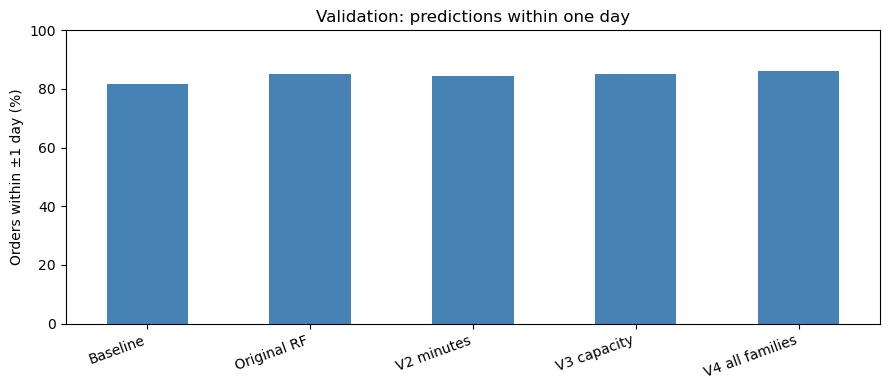

In [84]:
# Validation comparison: unrounded MAE and rounded-date accuracy

model_comparison = pd.DataFrame([
    {
        "model": "Baseline",
        "MAE": mean_absolute_error(
            val_orders["kit_cycle_days"],
            np.ones(len(val_orders))
        ),
        "within_1_day": (
            abs(val_orders["kit_cycle_days"] - 1) <= 1
        ).mean() * 100
    },
    {
        "model": "Original RF",
        "MAE": mean_absolute_error(val["kit_cycle_days"], predictions),
        "within_1_day": (
            abs(np.maximum(0, np.rint(predictions)) -
                val["kit_cycle_days"].to_numpy()) <= 1
        ).mean() * 100
    },
    {
        "model": "V2 minutes",
        "MAE": mean_absolute_error(actual_days_v2, predictions_v2),
        "within_1_day": (errors_v2 <= 1).mean() * 100
    },
    {
        "model": "V3 capacity",
        "MAE": mean_absolute_error(actual_days_v3, predictions_v3),
        "within_1_day": (errors_v3 <= 1).mean() * 100
    },
    {
        "model": "V4 all families",
        "MAE": mean_absolute_error(actual_days_v4, predictions_v4),
        "within_1_day": (errors_v4 <= 1).mean() * 100
    }
])

print(model_comparison.round(2).to_string(index=False))

ax = model_comparison.plot.bar(
    x="model",
    y="within_1_day",
    legend=False,
    figsize=(9, 4),
    color="steelblue"
)

ax.set(
    title="Validation: predictions within one day",
    ylabel="Orders within ±1 day (%)",
    xlabel=""
)

ax.set_ylim(0, 100)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

### Consistent test comparison

In [85]:
y = test_v4["kit_cycle_days"].to_numpy()
models = {
    "Baseline (1 day)": np.ones(len(y)),
    "Original RF": test_predictions,
    "RF V4": predictions_test_v4,
}
for name, p in models.items():
    pr = np.maximum(0, np.rint(p))
    print(f"{name:17s} MAE unrounded {np.abs(y-p).mean():.3f} | "
          f"rounded {np.abs(y-pr).mean():.3f} | "
          f"within 1 day {(np.abs(y-pr)<=1).mean()*100:.2f}%")

Baseline (1 day)  MAE unrounded 0.953 | rounded 0.953 | within 1 day 78.33%
Original RF       MAE unrounded 1.076 | rounded 1.036 | within 1 day 78.68%
RF V4             MAE unrounded 1.048 | rounded 1.029 | within 1 day 78.99%


## 10. Test errors and operational risk

Validation results are more optimistic than the later test results. Checks not only how often the date is correct, but whether it is predicted too early or too late.

In [86]:
#Error measure
# Compare predicted and actual KIT duration
error_analysis = test_v4[
    ["sales_order_id", "kit_start", "kit_cycle_days"]
].copy()

error_analysis["predicted_days"] = predicted_days_test_v4

# Positive error = predicted later than actual
# Negative error = predicted earlier than actual
error_analysis["error_days"] = (
    error_analysis["predicted_days"]
    - error_analysis["kit_cycle_days"]
)

print("V4 — TEST ERROR ANALYSIS")
print("------------------------")

print("Predicted too early:",
      (error_analysis["error_days"] < 0).sum())

print("Predicted exactly:",
      (error_analysis["error_days"] == 0).sum())

print("Predicted too late:",
      (error_analysis["error_days"] > 0).sum())

print("\nAverage signed error:",
      round(error_analysis["error_days"].mean(), 3))

print("\nError distribution:")
print(
    error_analysis["error_days"]
    .value_counts()
    .sort_index()
)

V4 — TEST ERROR ANALYSIS
------------------------
Predicted too early: 7698
Predicted exactly: 8864
Predicted too late: 10249

Average signed error: -0.126

Error distribution:
error_days
-39       1
-38       2
-36       2
-34       2
-32       2
-29       1
-23       1
-21       1
-19      30
-16       6
-14       3
-13       9
-12      13
-11      26
-10       4
-9       14
-8        6
-7        7
-6       49
-5      136
-4      365
-3      987
-2     2141
-1     3890
 0     8864
 1     8423
 2     1794
 3       28
 4        4
Name: count, dtype: int64


In [87]:
# types of orders are responsible for the large errors.
# Examine orders where the model was more than 2 days too early
large_early_errors = error_analysis[
    error_analysis["error_days"] < -2
].copy()

# Add order characteristics
large_early_errors = large_early_errors.merge(
    test_v4[
        ["sales_order_id", "total_line_qty",
         "num_families", "lob_desc"]
    ],
    on="sales_order_id",
    how="left"
)

print("Orders predicted more than 2 days too early:",
      len(large_early_errors))

print("\nActual KIT duration:")
print(large_early_errors["kit_cycle_days"].describe())

print("\nOrder quantity:")
print(large_early_errors["total_line_qty"].describe())

print("\nNumber of product families:")
print(large_early_errors["num_families"].describe())

print("\nTop lines of business:")
print(large_early_errors["lob_desc"].value_counts().head(10))

Orders predicted more than 2 days too early: 1667

Actual KIT duration:
count    1667.000000
mean        5.724655
std         3.753559
min         4.000000
25%         4.000000
50%         5.000000
75%         6.000000
max        40.000000
Name: kit_cycle_days, dtype: float64

Order quantity:
count    1667.000000
mean        2.725855
std         2.631387
min         1.000000
25%         1.000000
50%         1.000000
75%         4.000000
max        10.000000
Name: total_line_qty, dtype: float64

Number of product families:
count    1667.000000
mean        1.019796
std         0.143584
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max         3.000000
Name: num_families, dtype: float64

Top lines of business:
lob_desc
UTBJWJILJ                      1562
IJQQ XYTWFLJ TJR                 69
MDUJWHTSAJWLJI NSKWFX YWFSX      24
IFYF UWTYJHYNTS FUU YWFSX         9
XYTWFLJ NSYJLWFYJI TKKJW          2
XYTWFLJ ZSXYWZHYZWJI              1
Name: count, dtype: 

In [88]:
#Line of business prediction
# Add line of business to all test predictions
lob_error_analysis = error_analysis.merge(
    test_v4[["sales_order_id", "lob_desc"]],
    on="sales_order_id",
    how="left",
    validate="one_to_one"
)

# Flag severe underpredictions
lob_error_analysis["severe_early"] = (
    lob_error_analysis["error_days"] < -2
)

# Calculate error rate within each line of business
lob_risk = (
    lob_error_analysis.groupby("lob_desc")
    .agg(
        total_orders=("sales_order_id", "count"),
        severe_early_orders=("severe_early", "sum"),
        average_actual_days=("kit_cycle_days", "mean")
    )
    .reset_index()
)

lob_risk["severe_early_rate_pct"] = (
    lob_risk["severe_early_orders"]
    / lob_risk["total_orders"] * 100
)

print(
    lob_risk.sort_values(
        "severe_early_orders",
        ascending=False
    ).to_string(index=False)
)

                   lob_desc  total_orders  severe_early_orders  average_actual_days  severe_early_rate_pct
                  UTBJWJILJ         24359                 1562             1.658976               6.412414
           IJQQ XYTWFLJ TJR           881                   69             2.026107               7.832009
MDUJWHTSAJWLJI NSKWFX YWFSX           942                   24             1.521231               2.547771
  IFYF UWTYJHYNTS FUU YWFSX           412                    9             1.606796               2.184466
   XYTWFLJ NSYJLWFYJI TKKJW             3                    2             3.000000              66.666667
       XYTWFLJ ZSXYWZHYZWJI           208                    1             1.687500               0.480769
            IFYF RFSFLJRJSY             1                    0             1.000000               0.000000
            IJQQ SJYBTWPNSL             4                    0             1.500000               0.000000
             TJR SJYBTWPNSL          

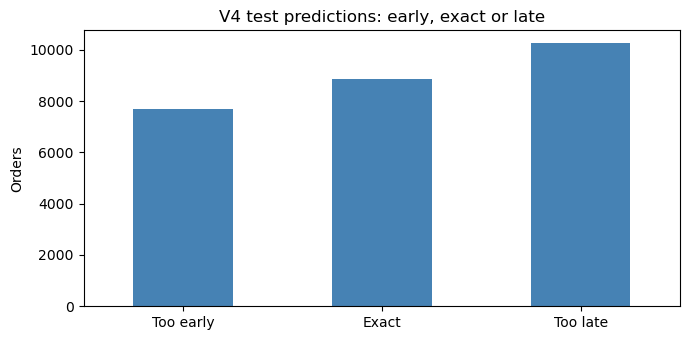

In [89]:
# Test-set early / exact / late predictions
error_group = pd.Series(np.select(
    [error_analysis["error_days"] < 0, error_analysis["error_days"] == 0],
    ["Too early", "Exact"], default="Too late"
)).value_counts().reindex(["Too early", "Exact", "Too late"])
ax = error_group.plot.bar(figsize=(7, 3.5), color="steelblue")
ax.set(title="V4 test predictions: early, exact or late", xlabel="", ylabel="Orders")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Changes in KIT duration over time

Later months contain more orders that take over two days. This may help explain the drop from validation to test performance, but it does not prove what caused the change.

In [90]:
print("TRAINING MONTHS")
print(
    train_known["kit_start"]
    .dt.to_period("M")
    .value_counts()
    .sort_index()
)

print("\nVALIDATION MONTHS")
print(
    val["kit_start"]
    .dt.to_period("M")
    .value_counts()
    .sort_index()
)

print("\nTEST MONTHS")
print(
    test["kit_start"]
    .dt.to_period("M")
    .value_counts()
    .sort_index()
)

TRAINING MONTHS
kit_start
2025-03    15731
2025-04    15838
2025-05    15981
2025-06    12688
2025-07    16995
2025-08    15186
2025-09    14009
2025-10    11626
Freq: M, Name: count, dtype: int64

VALIDATION MONTHS
kit_start
2025-10     5515
2025-11    14307
2025-12     5545
Freq: M, Name: count, dtype: int64

TEST MONTHS
kit_start
2025-12    11677
2026-01    15134
Freq: M, Name: count, dtype: int64


In [91]:
# Check whether KIT durations changed over time

monthly_duration = (
    order_features
    .assign(
        month=order_features["kit_start"].dt.to_period("M")
    )
    .groupby("month")
    .agg(
        orders=("sales_order_id", "count"),
        mean_days=("kit_cycle_days", "mean"),
        median_days=("kit_cycle_days", "median"),
        pct_over_2_days=(
            "kit_cycle_days",
            lambda x: (x > 2).mean() * 100
        )
    )
    .round(2)
)

print(monthly_duration)

         orders  mean_days  median_days  pct_over_2_days
month                                                   
2025-03   15731       1.96          2.0            27.72
2025-04   15838       1.16          1.0             9.57
2025-05   15981       1.41          1.0            15.06
2025-06   12688       1.11          1.0             9.36
2025-07   16995       0.98          1.0             6.95
2025-08   15186       1.25          1.0            10.13
2025-09   14010       1.25          1.0            11.08
2025-10   18421       1.23          1.0            10.82
2025-11   14307       1.64          1.0            19.77
2025-12   17222       1.72          1.0            23.01
2026-01   15134       1.50          1.0            16.37


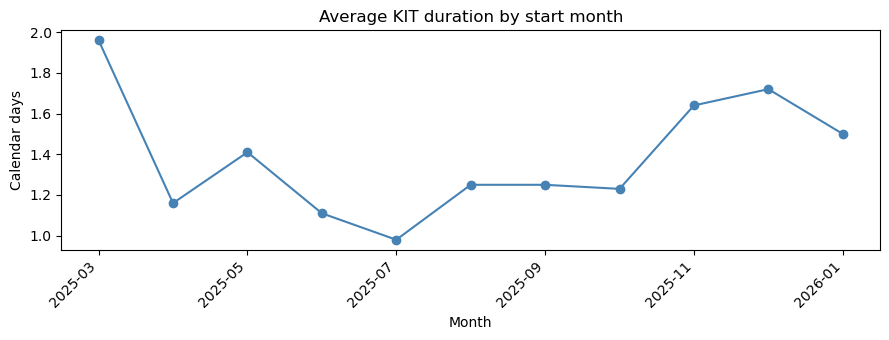

In [92]:
# Monthly duration and share of orders taking more than two days
monthly_plot = monthly_duration.copy()
monthly_plot.index = monthly_plot.index.astype(str)
ax = monthly_plot["mean_days"].plot(marker="o", figsize=(9, 3.5), color="steelblue")
ax.set(title="Average KIT duration by start month", xlabel="Month", ylabel="Calendar days")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Completion cutoff and potential selection bias

Training uses only orders completed before October 24, 2025. This avoids using labels unavailable at that date, but excludes some longer-running orders.

In [93]:
# Check training-data
# Orders that started before the training cutoff
started_before_cutoff = order_features[
    order_features["kit_start"] < "2025-10-24"
].copy()

# Orders whose completion date was not yet known at cutoff
not_completed_by_cutoff = started_before_cutoff[
    started_before_cutoff["kit_end"] >= "2025-10-24"
].copy()

print("Orders started before cutoff:",
      len(started_before_cutoff))

print("Orders excluded due to completion cutoff:",
      len(not_completed_by_cutoff))

print("Percentage excluded:",
      round(
          len(not_completed_by_cutoff)
          / len(started_before_cutoff) * 100, 2
      ), "%")

print("\nDuration of excluded orders:")
print(
    not_completed_by_cutoff["kit_cycle_days"].describe()
)

print("\nDuration of included training orders:")
print(
    train_known["kit_cycle_days"].describe()
)

Orders started before cutoff: 119335
Orders excluded due to completion cutoff: 1281
Percentage excluded: 1.07 %

Duration of excluded orders:
count    1281.000000
mean        2.404372
std         3.251747
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        34.000000
Name: kit_cycle_days, dtype: float64

Duration of included training orders:
count    118054.000000
mean          1.277348
std           1.305610
min           0.000000
25%           1.000000
50%           1.000000
75%           2.000000
max          76.000000
Name: kit_cycle_days, dtype: float64


## 11. Generate the inference predictions

I kept the original Random Forest for the final predictions. V4 did better on validation, but the improvement on the later test set was small, and its test MAE was slightly worse (1.048 versus 1.036 days). I refitted the original model on all valid historical orders before predicting the inference data. This final refit is separate from the earlier chronological evaluation.

In [94]:
# Model training with all completed historical orders
from sklearn.base import clone

final_model = clone(rf_model)

final_model.fit(
    order_features[features],
    order_features["kit_cycle_days"]
)

print("Final model trained successfully!")

Final model trained successfully!


In [95]:
dfinference = pd.read_parquet(r"C:\Users\admin\Downloads\Dell Data\inference.parquet")

In [96]:
print(dfinference.columns.tolist())

['sales_order_id', 'buid', 'site', 'orig_wo_id', 'tie_num', 'mcid', 'order_amt', 'quantity_produced', 'line_qty', 'cfs_flag', 'is_cfi', 'alt_type_desc', 'lob_desc', 'family_parent_desc', 'family_desc', 'download_date', 'kit_start', 'est_ship_date']


In [97]:
inference_features = dfinference.groupby(
    "sales_order_id"
).agg(
    kit_start=("kit_start", "first"),
    total_line_qty=("line_qty", "sum"),
    num_families=("family_desc", "nunique"),
    num_records=("family_desc", "size"),
    lob_desc=("lob_desc", "first"),
    alt_type_desc=("alt_type_desc", "first"),
    family_parent_desc=("family_parent_desc", "first")
).reset_index()

inference_features["start_weekday"] = (
    inference_features["kit_start"].dt.dayofweek
)

inference_features["start_month"] = (
    inference_features["kit_start"].dt.month
)

In [98]:
predicted_duration = final_model.predict(
    inference_features[features]
)

inference_features["predicted_cycle_days"] = np.maximum(
    0,
    np.rint(predicted_duration)
).astype(int)

inference_features["predicted_kit_end"] = (
    inference_features["kit_start"] +
    pd.to_timedelta(
        inference_features["predicted_cycle_days"],
        unit="D"
    )
)

inference_features[
    [
        "sales_order_id",
        "kit_start",
        "predicted_cycle_days",
        "predicted_kit_end"
    ]
].head(10)

,sales_order_id,kit_start,predicted_cycle_days,predicted_kit_end
0,399595192,2026-02-09,1,2026-02-10
1,399595207,2026-02-09,1,2026-02-10
2,401240140,2026-02-09,1,2026-02-10
3,401258291,2026-02-09,1,2026-02-10
4,401259231,2026-02-09,1,2026-02-10
5,401329191,2026-02-09,1,2026-02-10
6,401353793,2026-02-09,1,2026-02-10
7,401353808,2026-02-09,1,2026-02-10
8,401411173,2026-02-18,1,2026-02-19
9,401424378,2026-02-11,1,2026-02-12


In [99]:
inference_features["predicted_cycle_days"].value_counts().sort_index()

predicted_cycle_days
0      14
1    7656
2    3850
3     193
4      13
5      20
Name: count, dtype: int64

In [100]:
predictionkitdate = dfinference[["sales_order_id"]].merge(
    inference_features[
        ["sales_order_id", "predicted_kit_end"]
    ],
    on="sales_order_id",
    how="left",
    sort=False,
    validate="many_to_one"
)

predictionkitdate = predictionkitdate.rename(
    columns={"predicted_kit_end": "kit_end"}
)

# Verify predictions
assert len(predictionkitdate) == len(dfinference)
assert predictionkitdate["kit_end"].notna().all()

# Save
predictionkitdate.to_csv("kitting_predictions.csv", index=False)

print("Saved successfully!")
print("Rows:", len(predictionkitdate))
print(predictionkitdate.head())

Saved successfully!
Rows: 12069
   sales_order_id    kit_end
0      1026073335 2026-02-14
1      1027826085 2026-02-11
2      1029739753 2026-02-27
3      1030454098 2026-02-13
4      1029526599 2026-02-12


## 12. Findings and recommendations
**Model performance.** On the 26,811 test orders, the one-day baseline had an MAE of **0.953 days**, lower than the original Random Forest (**1.076**) and the full-family V4 model (**1.048**). The models were slightly more often within one day of the actual date (**78.68%** and **78.99%** versus **78.33%** for the baseline), but the gain is under one percentage point and was not tested for significance. V4 had the best validation result (MAE 0.797, 86.10% within one day), but that advantage did not carry over to the later test orders. V4 also used different forest settings from the original model, so its gain cannot be attributed to the family features alone. Overall, the models did not improve average error over the baseline, and gave only a marginal gain in within-one-day accuracy.

A likely reason is that a Random Forest trained on squared error predicts values near the mean, which the long-running orders pull upward, while the baseline (the median) is better suited to MAE. A model trained directly for MAE or a quantile target may do better.

**Where predictions fail.** V4 predicted 1,667 test orders (6.22%) more than two days too early. These orders actually took 4 or more days (average 5.7), were usually small, and typically had a single product family, so quantity and family count did not explain them. The severe-underprediction rate was 7.83% for one line of business (881 orders) and 6.41% for the largest (24,359 orders); that gap is small relative to the sample size and should not be read as a reliable difference. Start day also matters: orders starting on Saturday averaged 2.10 days, versus roughly 1.0–1.1 for Tuesday and Wednesday starts.

**Data issues.**
- 734 records (721 orders) had a KIT end date before the start date. 712 of them fall on three start dates, which suggests a systematic timestamp problem. I excluded them rather than guess corrected dates.
- The calendar file describes site FCJ, while the KIT records are KHO, so its weekend and holiday flags should not be assumed to apply.
- The capacity file does not say whether hours were known in advance. Capacity correlated with duration (-0.21), but adding it did not improve the model. It may largely reflect weekday, since Saturdays have lower capacity.
- Early-March orders appear to be limited by the extract window: every order starting on 4 March is a long one (8–10 days), and March averages 1.96 days versus about 1.2 for April–October. I did not test removing them.

**Changes over time.** Mean KIT duration rose from 1.23 days in October 2025 to 1.72 in December, and the share of orders over two days went from 10.8% to 23.0%. Training covers less than a year, and `start_month` is treated as an ordinary number, so seasonal effects are not established. The final model is applied to February starts, a month it has never seen, so those predictions may be less reliable.

**Selection bias.** Training only on orders completed before the cutoff (October 24, 2025) excluded 1,281 orders (1.07%) whose eventual mean duration was 2.40 days versus 1.28 for included orders.

**Final model.** I kept the original Random Forest for the inference predictions. V4 was marginally better on test (rounded MAE 1.029 versus 1.036; within one day 78.99% versus 78.68%), but the difference is very small, and the original model is simpler. It was refitted on all valid historical orders before predicting.

**Recommendations.**
- Treat predicted dates as planning estimates, not delivery commitments, especially for Saturday starts and small single-family orders.
- Build a classifier for orders likely to take 4 or more days, so delayed orders can be flagged before they start. The current model gives a single estimate and cannot do this.
- Try a model that predicts the median or higher quantiles of duration, and report an expected range alongside the date.
- Investigate the clustered negative timestamps and confirm which operational inputs (capacity, expected minutes) are actually known at the time an order starts.
- Collect a full year or more of history, exclude or investigate the early-March data, and monitor errors month by month before relying on the model.


## 13. Save and verify predictions

In [101]:
import numpy as np

predictions_array = predictionkitdate["kit_end"].to_numpy()

assert len(predictions_array) == len(dfinference)

np.save("predictions.npy", predictions_array)
print("Saved:", predictions_array.shape)

Saved: (12069,)


In [102]:
loaded = np.load("predictions.npy", allow_pickle=True)

print("Shape:", loaded.shape)
print("Data type:", loaded.dtype)
print("First 5 predictions:", loaded[:5])

Shape: (12069,)
Data type: datetime64[ns]
First 5 predictions: ['2026-02-14T00:00:00.000000000' '2026-02-11T00:00:00.000000000'
 '2026-02-27T00:00:00.000000000' '2026-02-13T00:00:00.000000000'
 '2026-02-12T00:00:00.000000000']


In [103]:
print("Inference columns:", dfinference.columns.tolist())
print("Prediction columns:", predictionkitdate.columns.tolist())

print("\nFirst 5 inference orders:")
print(dfinference["sales_order_id"].head())

print("\nFirst 5 predicted orders:")
print(predictionkitdate["sales_order_id"].head())

Inference columns: ['sales_order_id', 'buid', 'site', 'orig_wo_id', 'tie_num', 'mcid', 'order_amt', 'quantity_produced', 'line_qty', 'cfs_flag', 'is_cfi', 'alt_type_desc', 'lob_desc', 'family_parent_desc', 'family_desc', 'download_date', 'kit_start', 'est_ship_date']
Prediction columns: ['sales_order_id', 'kit_end']

First 5 inference orders:
0    1026073335
1    1027826085
2    1029739753
3    1030454098
4    1029526599
Name: sales_order_id, dtype: int64

First 5 predicted orders:
0    1026073335
1    1027826085
2    1029739753
3    1030454098
4    1029526599
Name: sales_order_id, dtype: int64


In [104]:
# Check that every prediction matches the original inference row order
same_order = (
    dfinference["sales_order_id"].reset_index(drop=True)
    .equals(
        predictionkitdate["sales_order_id"].reset_index(drop=True)
    )
)

print("All sales orders in original order:", same_order)
print("Inference rows:", len(dfinference))
print("Prediction rows:", len(predictionkitdate))
print("Missing predicted dates:",
      predictionkitdate["kit_end"].isna().sum())

All sales orders in original order: True
Inference rows: 12069
Prediction rows: 12069
Missing predicted dates: 0
